In [2]:
import platform
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer, f1_score, accuracy_score, classification_report, confusion_matrix,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
)

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ----------------------------
# 0) Config: paths & target
# ----------------------------
CSV_PATH   = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"  # Will auto-map if running in WSL
TARGET_COL = "isUnderAttack"   # integer labels {0,1,2,3}
RANDOM_SEED = 42

In [4]:
# ----------------------------
# ----------------------------
def windows_to_wsl_path(win_path: str) -> str:
    """Converts a Windows path to the equivalent WSL mount path if running under WSL."""
    try:
        is_wsl = ("microsoft" in platform.release().lower()) or ("microsoft" in platform.version().lower())
    except Exception:
        is_wsl = False
    if not is_wsl:
        return win_path
    p = Path(win_path)
    if str(p).startswith("/"):
        return str(p)  # already a Unix path
    drive = p.drive.replace(":", "").lower()
    rest = str(p).replace(p.drive, "").replace("\\", "/")
    return f"/mnt/{drive}{rest}"

In [5]:
# ----------------------------
# 2) Load data
# ----------------------------
csv_path = windows_to_wsl_path(CSV_PATH)
df = pd.read_csv(csv_path)

if TARGET_COL not in df.columns:
    raise ValueError(f"TARGET_COL '{TARGET_COL}' not found. Columns: {list(df.columns)}")

# Separate features and labels
X = df.drop(columns=[TARGET_COL]).values   # shape: (n_samples, n_features)
y = df[TARGET_COL].values                  # shape: (n_samples,)

In [6]:
# ----------------------------
# 3) Dataset summary
# ----------------------------
n_samples, n_features = X.shape
classes, counts = np.unique(y, return_counts=True)

print("=== Dataset Summary ===")
print(f"CSV path: {csv_path}")
print(f"Samples: {n_samples}")
print(f"Features: {n_features}")
print(f"Classes: {len(classes)}  -> {list(classes)}")
for c, cnt in zip(classes, counts):
    pct = 100.0 * cnt / n_samples
    print(f" - Class {c}: {cnt} samples ({pct:.2f}%)")
print("=" * 60)

=== Dataset Summary ===
CSV path: /mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv
Samples: 58025
Features: 10
Classes: 4  -> [0, 1, 2, 3]
 - Class 0: 25773 samples (44.42%)
 - Class 1: 12981 samples (22.37%)
 - Class 2: 12959 samples (22.33%)
 - Class 3: 6312 samples (10.88%)


In [7]:
# ----------------------------
# 4) Train/Test split (75:25), stratified to preserve class balance
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_SEED
)

print("Class distribution (train 75%):", Counter(y_train))
print("Class distribution (test  25%):", Counter(y_test))
print("-" * 60)

Class distribution (train 75%): Counter({0: 19329, 1: 9736, 2: 9719, 3: 4734})
Class distribution (test  25%): Counter({0: 6444, 1: 3245, 2: 3240, 3: 1578})
------------------------------------------------------------


In [8]:
# ----------------------------
# 5) CV settings & primary tuning metric
#    We optimize F1-macro to treat all classes equally (good for imbalance).
# ----------------------------
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
primary_metric_name = "f1_macro"
scorer = make_scorer(f1_score, average="macro")

In [9]:
# ----------------------------
# 6) Print the hyperparameter pool (what we investigate)
# ----------------------------
PARAM_SEARCH_SPACE = {
    "penalty": ["l1", "l2"],
    "C":      "[1e-4, 1e+3] (log-uniform)",
    "tol":    "[1e-6, 1e-3] (log-uniform)",
    "class_weight": [None, "balanced"],
    "solver": 'derived: "saga" if L1 else "lbfgs"',
    "multi_class": 'fixed: "multinomial"',
    "max_iter": '5000 if L1 else 3000'
}
print("Hyperparameter pool (search space):")
for k, v in PARAM_SEARCH_SPACE.items():
    print(f" - {k}: {v}")
print("-" * 60)

Hyperparameter pool (search space):
 - penalty: ['l1', 'l2']
 - C: [1e-4, 1e+3] (log-uniform)
 - tol: [1e-6, 1e-3] (log-uniform)
 - class_weight: [None, 'balanced']
 - solver: derived: "saga" if L1 else "lbfgs"
 - multi_class: fixed: "multinomial"
 - max_iter: 5000 if L1 else 3000
------------------------------------------------------------


In [10]:
# ----------------------------
# 7) Pipeline builder: scaler → logistic regression
#    Ensures valid (penalty, solver) combos.
# ----------------------------
def make_pipeline(params):
    """
    params:
      - penalty: "l1" or "l2"
      - C: float (1e-4 .. 1e3, log scale)
      - tol: float (1e-6 .. 1e-3, log scale)
      - class_weight: None or "balanced"
    Notes:
      - L1 requires solver="saga"; supports multinomial.
      - L2 uses solver="lbfgs" (fast & stable); supports multinomial.
    """
    penalty = params["penalty"]
    if penalty == "l1":
        solver = "saga"
        max_iter = 5000
    else:
        solver = "lbfgs"
        max_iter = 3000

    clf = LogisticRegression(
        solver=solver,
        penalty=penalty,
        C=params["C"],
        tol=params["tol"],
        class_weight=params["class_weight"],
        multi_class="multinomial",   # proper for 4-class setting
        max_iter=max_iter,
        random_state=0
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

In [11]:
# ----------------------------
# 8) Optuna objective: 10-fold CV on TRAIN ONLY
# ----------------------------
def objective(trial):
    params = {
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "C": trial.suggest_float("C", 1e-4, 1e3, log=True),
        "tol": trial.suggest_float("tol", 1e-6, 1e-3, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    pipe = make_pipeline(params)
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=scorer, n_jobs=-1)
    return float(np.mean(scores))

In [12]:
# ----------------------------
# 9) Run Optuna (TPE). Increase n_trials for deeper search.
# ----------------------------
study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
print("[Optuna] Optimizing…")
study.optimize(objective, n_trials=80, show_progress_bar=False)

print(f"[Optuna] Best {primary_metric_name}: {study.best_value:.6f}")
print("[Optuna] Best params:", study.best_trial.params)
best_params = study.best_trial.params

[I 2025-10-14 15:23:50,373] A new study created in memory with name: no-name-f6d0a80b-cbbd-487f-8747-d22e25782981


[Optuna] Optimizing…


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning

[Optuna] Best f1_macro: 0.967809
[Optuna] Best params: {'penalty': 'l2', 'C': 965.9184849666412, 'tol': 1.9148577409664156e-05, 'class_weight': None}


In [13]:
# ----------------------------
# 10) Build best pipeline & report CV metrics (train folds)
# ----------------------------
best_pipe = make_pipeline(best_params)

cv_f1 = cross_val_score(best_pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"[CV on train] F1-macro: mean={cv_f1.mean():.6f}  std={cv_f1.std():.6f}")

cv_acc = cross_val_score(best_pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
print(f"[CV on train] Accuracy:  mean={cv_acc.mean():.6f}  std={cv_acc.std():.6f}")

# OOF predictions for detailed CV report (train set)
y_pred_cv = cross_val_predict(best_pipe, X_train, y_train, cv=cv, n_jobs=-1)
print("\n=== Classification report (CV predictions on train) ===")
print(classification_report(y_train, y_pred_cv, digits=4))
print("=== Confusion matrix (CV predictions on train) ===")
print(confusion_matrix(y_train, y_pred_cv))
print("-" * 60)

/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning

[CV on train] F1-macro: mean=0.967809  std=0.001250


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning

[CV on train] Accuracy:  mean=0.964337  std=0.001460


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning


=== Classification report (CV predictions on train) ===
              precision    recall  f1-score   support

           0     0.9488    0.9824    0.9653     19329
           1     0.9711    0.9666    0.9689      9736
           2     0.9753    0.9113    0.9422      9719
           3     0.9949    0.9947    0.9948      4734

    accuracy                         0.9643     43518
   macro avg     0.9726    0.9638    0.9678     43518
weighted avg     0.9647    0.9643    0.9642     43518

=== Confusion matrix (CV predictions on train) ===
[[18989   110   208    22]
 [  309  9411    16     0]
 [  693   167  8857     2]
 [   22     3     0  4709]]
------------------------------------------------------------


In [14]:
# ----------------------------
# 11) Fit on full TRAIN; evaluate on TEST
# ----------------------------
best_pipe.fit(X_train, y_train)
print("Final tuned model fitted on the full training set.")

y_pred_test  = best_pipe.predict(X_test)
y_proba_test = best_pipe.predict_proba(X_test)  # needed for ROC/PR curves

test_acc = accuracy_score(y_test, y_pred_test)
test_f1_macro = f1_score(y_test, y_pred_test, average="macro")
test_f1_weighted = f1_score(y_test, y_pred_test, average="weighted")

print("\n=== Test set evaluation (held-out 25%) ===")
print(f"Accuracy:           {test_acc:.6f}")
print(f"F1 (macro):         {test_f1_macro:.6f}")
print(f"F1 (weighted):      {test_f1_weighted:.6f}")
print("\nClassification report (test):")
print(classification_report(y_test, y_pred_test, digits=4))
print("Confusion matrix (test):")
cm = confusion_matrix(y_test, y_pred_test)
print(cm)
print("-" * 60)


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Final tuned model fitted on the full training set.

=== Test set evaluation (held-out 25%) ===
Accuracy:           0.964155
F1 (macro):         0.967859
F1 (weighted):      0.964043

Classification report (test):
              precision    recall  f1-score   support

           0     0.9465    0.9828    0.9643      6444
           1     0.9725    0.9587    0.9655      3245
           2     0.9783    0.9182    0.9473      3240
           3     0.9949    0.9937    0.9943      1578

    accuracy                         0.9642     14507
   macro avg     0.9731    0.9633    0.9679     14507
weighted avg     0.9647    0.9642    0.9640     14507

Confusion matrix (test):
[[6333   42   61    8]
 [ 129 3111    5    0]
 [ 220   45 2975    0]
 [   9    1    0 1568]]
------------------------------------------------------------


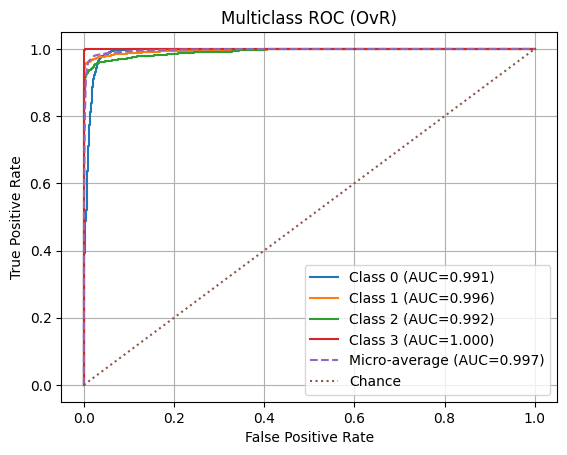

TPR at FPR=1%:
 - Class 0: 0.7017
 - Class 1: 0.9602
 - Class 2: 0.9309
 - Class 3: 1.0000
Macro-average: 0.8982
------------------------------------------------------------
TPR at FPR=5%:
 - Class 0: 0.9842
 - Class 1: 0.9778
 - Class 2: 0.9633
 - Class 3: 1.0000
Macro-average: 0.9813
------------------------------------------------------------


In [15]:
# ----------------------------
# 12) Multiclass ROC (One-vs-Rest) + AUC; and TPR at fixed FPRs
# ----------------------------
unique_classes = np.unique(y_train)
n_classes = len(unique_classes)

# Binarize y for OvR ROC/PR computation
y_test_bin = label_binarize(y_test, classes=unique_classes)  # shape: (n_samples, n_classes)

# Per-class ROC data
fpr = {}
tpr = {}
roc_auc = {}
for i, cls in enumerate(unique_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_proba_test[:, i])
    roc_auc[i] = roc_auc_score(y_test_bin[:, i], y_proba_test[:, i])

# Micro-average ROC/AUC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_proba_test.ravel())
roc_auc["micro"] = roc_auc_score(y_test_bin, y_proba_test, average="micro", multi_class="ovr")

# Macro-average AUC (mean of per-class AUCs)
roc_auc["macro"] = np.mean([roc_auc[i] for i in range(n_classes)])

# Plot ROC curves
plt.figure()
for i, cls in enumerate(unique_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {cls} (AUC={roc_auc[i]:.3f})")
plt.plot(fpr["micro"], tpr["micro"], linestyle="--", label=f"Micro-average (AUC={roc_auc['micro']:.3f})")
plt.plot([0, 1], [0, 1], linestyle=":", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC (OvR)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Function to interpolate TPR at a fixed FPR
def tpr_at_fixed_fpr(fpr_array, tpr_array, target_fpr):
    """Linear interpolation of TPR at a given FPR (target_fpr in [0,1])."""
    target_fpr = float(np.clip(target_fpr, 0.0, 1.0))
    return float(np.interp(target_fpr, fpr_array, tpr_array))

# Report TPR at FPR = 1% and 5%
for target in [0.01, 0.05]:
    per_class = []
    print(f"TPR at FPR={int(target*100)}%:")
    for i, cls in enumerate(unique_classes):
        val = tpr_at_fixed_fpr(fpr[i], tpr[i], target)
        per_class.append(val)
        print(f" - Class {cls}: {val:.4f}")
    print(f"Macro-average: {np.mean(per_class):.4f}")
    print("-" * 60)


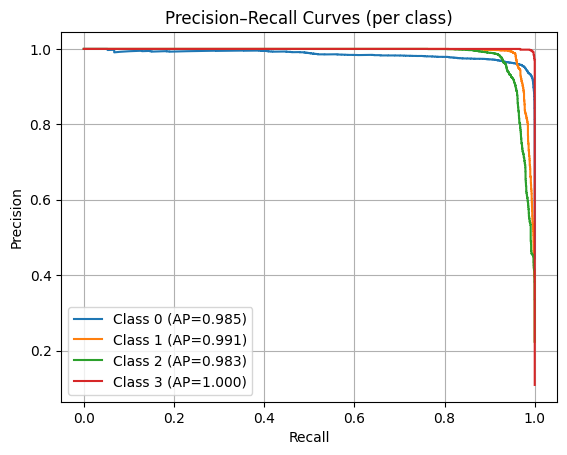

Average Precision (AP) per class (test):
 - Class 0: AP = 0.985399
 - Class 1: AP = 0.990939
 - Class 2: AP = 0.982988
 - Class 3: AP = 0.999861
Micro-average AP: 0.990437
Macro-average AP: 0.989797
------------------------------------------------------------


In [16]:
# ----------------------------
# 13) Precision–Recall curves + Average Precision per class
# ----------------------------
precision = {}
recall = {}
avg_precision = {}

for i, cls in enumerate(unique_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_proba_test[:, i])
    avg_precision[i] = average_precision_score(y_test_bin[:, i], y_proba_test[:, i])

# Micro- and macro-average AP
avg_precision["micro"] = average_precision_score(y_test_bin, y_proba_test, average="micro")
avg_precision["macro"] = np.mean([avg_precision[i] for i in range(n_classes)])

# Plot PR curves
plt.figure()
for i, cls in enumerate(unique_classes):
    plt.plot(recall[i], precision[i], label=f"Class {cls} (AP={avg_precision[i]:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves (per class)")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()

print("Average Precision (AP) per class (test):")
for i, cls in enumerate(unique_classes):
    print(f" - Class {cls}: AP = {avg_precision[i]:.6f}")
print(f"Micro-average AP: {avg_precision['micro']:.6f}")
print(f"Macro-average AP: {avg_precision['macro']:.6f}")
print("-" * 60)

In [17]:
# ----------------------------
# 14) Optional: If L1 won, show sparsity
# ----------------------------
final_clf = best_pipe.named_steps["clf"]
if best_params["penalty"] == "l1":
    coef = final_clf.coef_              # shape: (n_classes, n_features)
    total = coef.size
    zeros = np.sum(coef == 0.0)
    print(f"Sparsity with L1: {zeros}/{total} coefficients are exactly zero "
          f"({100.0 * zeros / total:.2f}%).")

In [18]:
# ----------------------------
# 15) Print final classifier config (for records)
# ----------------------------
print("\nUse this classifier configuration going forward:")
print(final_clf)


Use this classifier configuration going forward:
LogisticRegression(C=965.9184849666412, max_iter=3000,
                   multi_class='multinomial', random_state=0,
                   tol=1.9148577409664156e-05)


In [19]:
import os
import joblib
from datetime import datetime

# ----------------------------
# 16) Save the best trained model as .pkl
# ----------------------------

# Create directory if not exists
save_dir = "best_model_trained_after_parameter_tuning"
os.makedirs(save_dir, exist_ok=True)

# Build filename with timestamp for traceability
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_path = os.path.join(save_dir, f"LR_best_model_{timestamp}.pkl")

# Dump the pipeline (scaler + logistic regression)
joblib.dump(best_pipe, save_path)

print(f"\nBest tuned Logistic Regression model saved to:\n{save_path}")



Best tuned Logistic Regression model saved to:
best_model_trained_after_parameter_tuning/LR_best_model_20251014_154700.pkl
